# Datavidia 11.0 — Task 2: Klasifikasi Jenis Fenomena dari Pasangan Citra Udara

**Tujuan.** Untuk setiap `Id` (sepasang citra `pre.jpg` / `post.jpg`), prediksi satu dari enam kelas:
`Earthquake`, `Fire`, `Hurricane`, `Tsunami`, `Volcano`, `Explosion`. Metrik: **Macro F1**, jadi setiap kelas berbobot sama,
termasuk kelas yang jarang.

**Fakta kunci dari data.** Tidak ada label latih: folder `Fenomena/` berisi 3.180 pasangan, dan semuanya adalah data yang
harus diprediksi. Karena itu solusi ini **tidak melatih classifier dengan label**. Pipeline-nya:

1. **Reduksi noise** (citra dirusak sengaja oleh panitia): mask padding hasil warp, hapus *salt-and-pepper*, hapus *stripe*
   horizontal, normalisasi warna per kanal, deteksi awan sintetis.
2. **Representasi**: embedding DINOv2-L dan CLIP-L (dirata-rata 4 rotasi, pooling hanya pada patch valid tanpa awan).
3. **Bukti zero-shot**: vision-language model Qwen3-VL (8B, citra berwarna; 4B, citra grayscale) menjawab pertanyaan pilihan
   ganda per pasangan, plus skor perubahan CLIP (teks vs citra sebelum/sesudah).
4. **Label model**: kalibrasi bias tiap sinyal, *deconfounding* terhadap variabel korupsi (awan, grayscale, stripe, dll.),
   fusi, propagasi di graf kNN "event" (tile dari bencana yang sama saling berdekatan), dan penyesuaian prior kelas
   (Earthquake ~22%, diturunkan dari skor 0,06 sample submission).
5. **Prediksi** → `submission.csv`.

Notebook ini menjalankan **inferensi tanpa melatih ulang**: semua backbone adalah model pralatih, VLM dipakai zero-shot,
dan parameter label model dimuat dari `models/`. Langkah berat menyimpan hasil ke `exp/cache/` dan dilewati bila cache ada.

## 0. Setup

Dependensi ada di `requirements.txt`. Bobot model pralatih diunduh otomatis dari Hugging Face saat pertama kali dijalankan
(`facebook/dinov2-with-registers-large`, `timm/vit_large_patch14_clip_336.openai`, `Qwen/Qwen3-VL-8B-Instruct`,
`Qwen/Qwen3-VL-4B-Instruct`) ke `.cache/hf`. GPU >= 12 GB diperlukan untuk langkah VLM (8B dimuat 4-bit).

In [1]:
import sys, os, json, time, platform
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / 'code'))
os.environ.setdefault('HF_HOME', str(ROOT / '.cache' / 'hf'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2, torch
import t2pipe
from common import CACHE, VIZ, MODELS, IMG_DIR, CLASSES, list_ids, read_rgb, clean_image, valid_mask
pd.set_option('display.width', 160)
print('python', platform.python_version(), '| torch', torch.__version__, '| cuda', torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
TAG = 'final'

python 3.13.5 | torch 2.11.0+cu128 | cuda True NVIDIA GeForce RTX 3060


## 1. Memahami data

In [2]:
ids = list_ids()
dirs = sorted(os.listdir(IMG_DIR))
print('pasangan di sample_submission:', len(ids), '| folder:', len(dirs), '| cocok:', set(ids) == set(dirs))
sizes = {}
for i in ids[:200]:
    for w in ('pre', 'post'):
        im = cv2.imread(str(IMG_DIR / i / f'{w}.jpg'))
        sizes[im.shape] = sizes.get(im.shape, 0) + 1
print('ukuran citra (200 pasangan pertama):', sizes)

pasangan di sample_submission: 3180 | folder: 3180 | cocok: True


ukuran citra (200 pasangan pertama): {(1024, 1024, 3): 400}


Semua citra 1024x1024 RGB. **Tidak ada label**, sehingga ini masalah *unsupervised / zero-shot*. Satu-satunya informasi
label adalah kalimat di halaman Evaluation: submission berisi `Earthquake` semua mendapat ~0,06. Untuk prediksi konstan,
F1 kelas Earthquake = 2p/(1+p) dan kelas lain 0, sehingga Macro F1 = 2p/(6(1+p)) = 0,06 → **p ≈ 0,22** (sekitar 700 pasangan
Earthquake). Angka ini dipakai sebagai jangkar prior kelas.

In [3]:
p = np.linspace(0.15, 0.30, 301); mf1 = 2 * p / (1 + p) / 6
for target in (0.055, 0.06, 0.065):
    print(f'skor all-Earthquake {target:.3f} -> porsi Earthquake ~ {p[np.argmin(abs(mf1 - target))]:.3f}')

skor all-Earthquake 0.055 -> porsi Earthquake ~ 0.198
skor all-Earthquake 0.060 -> porsi Earthquake ~ 0.220
skor all-Earthquake 0.065 -> porsi Earthquake ~ 0.242


## 2. EDA noise: apa saja yang dirusak panitia?

Inspeksi visual menunjukkan enam jenis gangguan: (a) padding hitam akibat rotasi/perspektif, (b) *salt-and-pepper*,
(c) *stripe* horizontal (offset per baris), (d) blur, (e) pergeseran warna (tint, grayscale, kanal tertukar), (f) awan sintetis.
`code/01_noise_survey.py` mengukur tiap gangguan pada 6.360 citra.

In [4]:
if not (CACHE / 'noise_survey.csv').exists():
    t2pipe._run('01_noise_survey.py')
ns = pd.read_csv(CACHE / 'noise_survey.csv')
pre, post = ns[ns.which == 'pre'].reset_index(drop=True), ns[ns.which == 'post'].reset_index(drop=True)
summary = pd.Series({
    'padding warp > 1% citra': (ns.border_frac > .01).mean(),
    'padding warp > 10% citra': (ns.border_frac > .10).mean(),
    'salt-and-pepper > 0,2% piksel': (ns.impulse_frac > .002).mean(),
    'stripe baris kuat (row > 2x col)': (ns.stripe_row > 2 * ns.stripe_col).mean(),
    'awan > 5% citra (detektor v1)': (ns.cloud_frac > .05).mean(),
    'pasangan grayscale (pre & post)': ((pre.chroma_spread < 2) & (post.chroma_spread < 2)).mean(),
    'korelasi stripe pre vs post': np.corrcoef(pre.stripe_row, post.stripe_row)[0, 1],
}).round(3)
display(summary.to_frame('nilai'))
print('median skor stripe: sebelum', ns.stripe_row.median().round(2), '-> sesudah destripe', ns.stripe_row_after.median().round(2))
print('p90 skor stripe:    sebelum', ns.stripe_row.quantile(.9).round(2), '-> sesudah destripe', ns.stripe_row_after.quantile(.9).round(2))

,nilai
padding warp > 1% citra,0.836
padding warp > 10% citra,0.084
"salt-and-pepper > 0,2% piksel",0.359
stripe baris kuat (row > 2x col),0.383
awan > 5% citra (detektor v1),0.091
pasangan grayscale (pre & post),0.075
korelasi stripe pre vs post,0.026


median skor stripe: sebelum 2.19 -> sesudah destripe 0.94
p90 skor stripe:    sebelum 9.41 -> sesudah destripe 1.7


Temuan: noise diterapkan **independen** antara pre dan post (korelasi stripe ~0), kecuali grayscale yang selalu mengenai
kedua citra sepasang. Urutan kanal juga sering tertukar (kanal biru paling terang pada ~12% citra, hal yang jarang terjadi
pada citra udara alami), sehingga **warna absolut tidak bisa dipercaya**; fitur yang tahan warna menjadi penting.

## 3. Preprocessing (reduksi noise)

Rantai pembersihan (`code/common.py`, `code/02_clean_cache.py`, `code/10_cloud_v2.py`):

| Gangguan | Penanganan | Alasan |
|---|---|---|
| Padding warp | *flood fill* piksel hampir-hitam dari tepi → mask valid; diisi warna rata-rata | bayangan gelap di dalam citra tidak ikut terhapus |
| Salt-and-pepper | median 3x3 **hanya** pada piksel yang menyimpang > 40 | detail lain tetap utuh |
| Stripe horizontal | high-pass vertikal → median per baris → dikurangi | offset per baris sama di semua kolom, konten tidak |
| Blur + resolusi | downsample area ke 512 | citra sudah blur; 512 cukup dan meredam noise |
| Tint / gain kanal | stretch persentil 1-99 per kanal | menghapus cast warna global |
| Kanal tertukar / grayscale | fitur event memakai **versi grayscale**; VLM melihat versi warna dan grayscale | lihat bagian 4 |
| Awan sintetis | detektor v2: terang, saturasi rendah, halus, **besar, tepi lembut**; diisi warna rata-rata dan di-mask saat pooling | v1 salah mendeteksi atap putih/salju/pasir |

Dicoba lalu **ditolak**: kanonisasi hue berbasis histogram (memaksa semua citra menjadi hijau) dan jaringan hue
self-supervised (`code/08_hue_canon.py`, `code/09_hue_net.py`; hanya mengoreksi pergeseran kecil, tint ungu tetap).

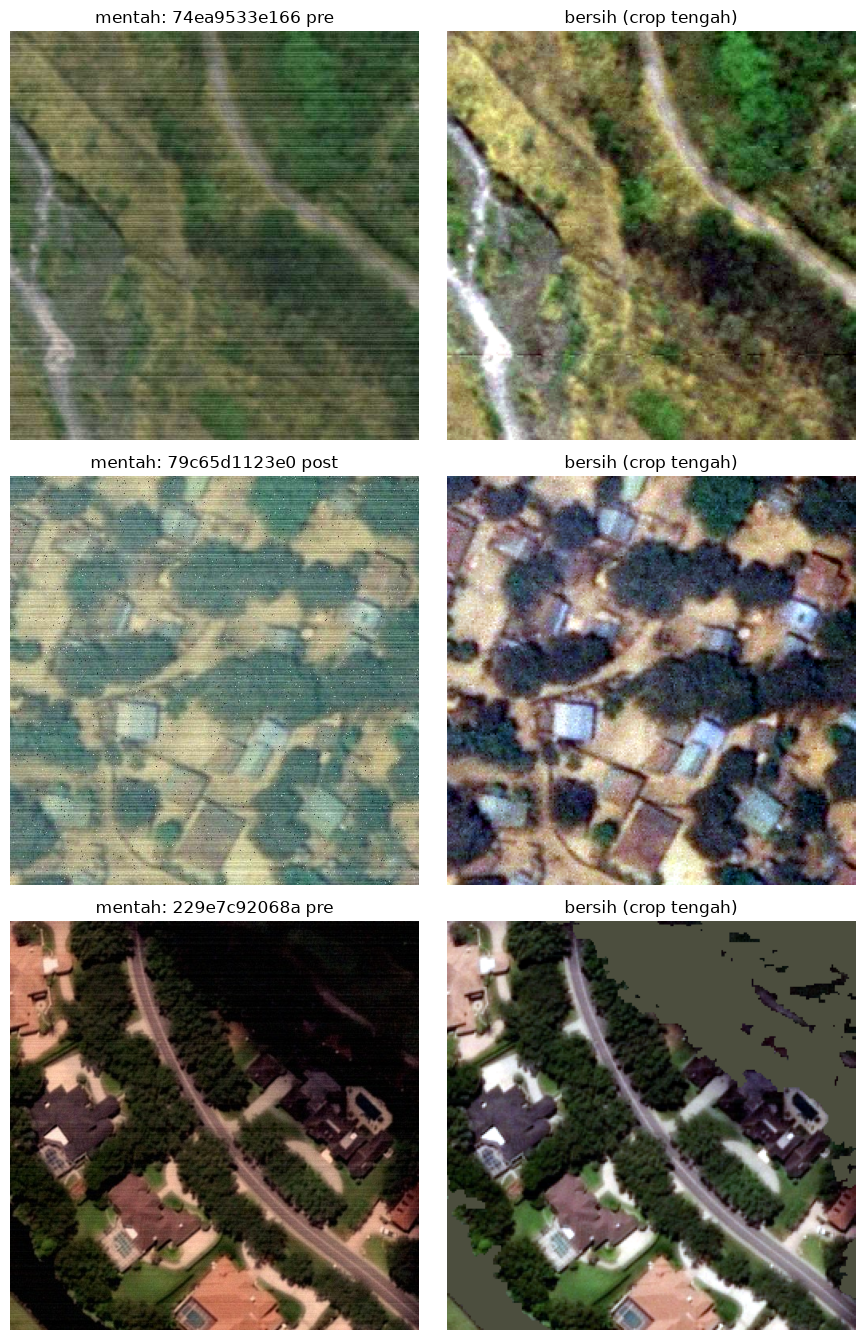

In [5]:
ex = ns.sort_values('stripe_row').iloc[-3], ns.sort_values('impulse_frac').iloc[-3], ns.sort_values('border_frac').iloc[-40]
fig, ax = plt.subplots(len(ex), 2, figsize=(9, 4.5 * len(ex)))
for r, row in enumerate(ex):
    rgb = read_rgb(IMG_DIR / row.id / f'{row.which}.jpg')
    clean, vm, cm = clean_image(rgb, 512)
    ax[r, 0].imshow(rgb[256:768, 256:768]); ax[r, 0].set_title(f'mentah: {row.id} {row.which}')
    ax[r, 1].imshow(clean[128:384, 128:384]); ax[r, 1].set_title('bersih (crop tengah)')
    for a in ax[r]: a.axis('off')
plt.tight_layout(); plt.show()

In [6]:
t0 = time.time(); t2pipe.step_clean(); print(f'cache citra bersih siap ({time.time()-t0:.0f}s)')
c1 = np.load(CACHE / 'cloud64v1_post.npy').max((1, 2)) > .25
c2 = np.load(CACHE / 'cloud64_post.npy').max((1, 2)) > .25
print(f'citra post dengan "awan": detektor v1 {c1.mean():.3f} -> v2 {c2.mean():.3f}')

cache citra bersih siap (0s)
citra post dengan "awan": detektor v1 0.604 -> v2 0.171


## 4. Representasi citra dan uji kualitas tanpa label

Embedding diekstrak dari **DINOv2-L (with registers)** dan **CLIP ViT-L/14-336**, masing-masing pada versi warna
ternormalisasi (`rgbn`) dan versi luminans (`gray`). Setiap embedding dirata-rata atas 4 rotasi 90° (citra udara tidak punya
arah "atas") dan patch-token di-*pool* hanya pada sel valid tanpa awan.

**Uji tanpa label:** pre dan post dari satu pasangan adalah tempat yang sama tetapi dirusak secara independen. Embedding yang
baik harus bisa menemukan citra pre pasangannya dari citra post-nya di antara 3.180 kandidat (acak: 0,03%).

In [7]:
t2pipe.step_embed()
import importlib; ev = importlib.import_module('04_embed_eval')
rows = []
for name in ['emb_dinov2l_gray', 'emb_dinov2l_rgbn', 'emb_clipl_rgbn', 'emb_clipl_gray']:
    a, b = np.load(CACHE / f'{name}_pre.npz')['patch'], np.load(CACHE / f'{name}_post.npz')['patch']
    r = ev.evaluate(*ev.prep(a, b, whiten=True)); r['embedding'] = name; rows.append(r)
display(pd.DataFrame(rows).set_index('embedding').round(3))

,r1,r10,mrr,same_k20
embedding,,,,
emb_dinov2l_gray,0.428,0.650,0.504,0.586
emb_dinov2l_rgbn,0.458,0.685,0.534,0.569
emb_clipl_rgbn,0.385,0.603,0.458,0.494
emb_clipl_gray,0.376,0.599,0.451,0.475


DINOv2 paling kuat mengenali lokasi (R@1 ~0,43-0,46). Untuk struktur *event* dipakai versi **grayscale**: dengan fitur warna,
pasangan grayscale membentuk klaster sendiri (artefak), sedangkan dengan fitur grayscale tidak.

In [8]:
from sklearn.cluster import KMeans
lm = importlib.import_module('12_label_model')
gray_pair = (pre.chroma_spread.values < 2) & (post.chroma_spread.values < 2)
for nm, spec in [('warna+gray', (('dinov2l_rgbn', 'patch', 128), ('dinov2l_gray', 'patch', 128), ('clipl_rgbn', 'cls', 64))),
                 ('gray saja (dipakai)', (('dinov2l_gray', 'patch', 128), ('clipl_gray', 'patch', 64)))]:
    lab = KMeans(40, n_init=4, random_state=0).fit_predict(lm.event_features(spec))
    share = max(gray_pair[lab == c].mean() for c in range(40))
    print(f'{nm:20s}: porsi pasangan grayscale tertinggi dalam satu klaster = {share:.2f}')

warna+gray          : porsi pasangan grayscale tertinggi dalam satu klaster = 0.78


gray saja (dipakai) : porsi pasangan grayscale tertinggi dalam satu klaster = 0.16


## 5. Struktur event

Satu bencana (mis. satu gempa di satu kota) menyumbang banyak tile yang mirip: arsitektur, vegetasi, medan, sensor.
Peta UMAP dari embedding pasangan memperlihatkan "pulau-pulau" event; HDBSCAN menemukan ~37 pulau.
Inilah alasan bisnis/proses utama di balik label model: **tile tanpa kerusakan terlihat tetap bisa diklasifikasi lewat
tetangganya dari event yang sama**, persis seperti analis yang memakai konteks lokasi.

pulau HDBSCAN: 37 | porsi noise: 0.208


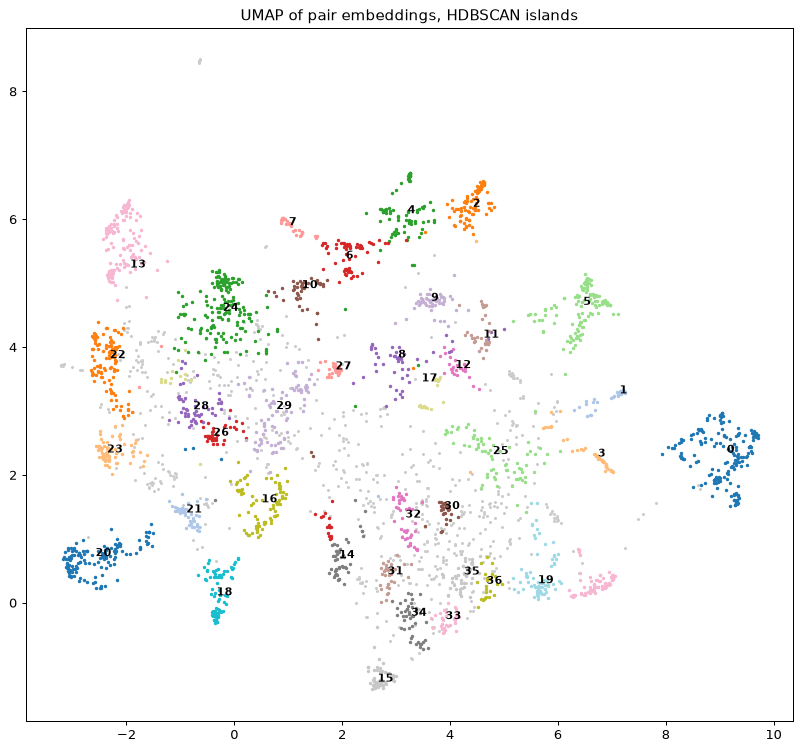

In [9]:
from IPython.display import Image as IPImage, display as D
if not (CACHE / 'hdb_labels.npy').exists() or not (VIZ / 'event_map.png').exists():
    t2pipe._run('11_event_map.py')   # UMAP 2-D + HDBSCAN pada embedding pasangan
lab_h = np.load(CACHE / 'hdb_labels.npy')
print('pulau HDBSCAN:', lab_h.max() + 1, '| porsi noise:', round((lab_h < 0).mean(), 3))
D(IPImage(str(VIZ / 'event_map.png'), width=700))

## 6. Bukti zero-shot

### 6.1 VLM per pasangan
Qwen3-VL menerima citra *before* dan *after* plus pertanyaan pilihan ganda berisi deskripsi tiap kelas. Kita membaca logit
token huruf A-F (tanpa generate) dan merata-rata 3 urutan opsi untuk menetralkan bias posisi. Pertanyaan kedua (Yes/No)
mengukur apakah kerusakan terlihat. Dua run: **8B (4-bit) pada citra warna** dan **4B pada citra grayscale**
(model dan tampilan berbeda → kesalahan lebih independen).

In [10]:
vlm = importlib.import_module('05_vlm_zeroshot')
print(vlm.QUESTION.format(opts='\n'.join(f'{vlm.LETTERS[j]}. {vlm.DESC[c]}' for j, c in enumerate(CLASSES))))
cfg = t2pipe.load_config(TAG)
print(json.dumps(cfg, indent=1))
t2pipe.step_vlm(cfg['pipeline'])

These are two aerial images of the same location. The first was taken BEFORE a disaster, the second AFTER it. The images may be rotated, blurred or colour-shifted, and flat single-colour regions are missing data (removed clouds or borders); ignore all of those artefacts. Which type of disaster most likely affected this area?
A. Earthquake (ground shaking: collapsed or cracked buildings and rubble spread across a town)
B. Fire (wildfire or urban fire: burned, blackened or grey ash ground, scorched vegetation, houses burned to their foundations)
C. Hurricane (tropical storm wind and rain: roofs torn off, blue tarps, fallen or stripped trees, scattered debris, flooding)
D. Tsunami (sea wave flooding the coast: buildings washed away, mud and debris over land, changed shoreline)
E. Volcano (eruption: lava flows, grey volcanic ash or mud covering land, roads and buildings)
F. Explosion (a large blast: buildings destroyed around one point with damage radiating outwards, often an industrial or

Temuan penting: **VLM sangat bias** dan bias ini berbeda antar model (4B condong ke *Volcano*, 8B condong ke *Fire*), serta
sensitif terhadap kata dalam prompt (menambah kalimat "salju bukan abu" membuat 4B menjawab Volcano 90/96). Karena itu
skor mentah tidak dipakai langsung; setiap sinyal **dikalibrasi** dengan mengurangkan rata-rata log-prob per kelas
di seluruh data (menghapus bias global) lalu distandardisasi. Setelah kalibrasi, 8B dan 4B sepakat jauh di atas acak.

In [11]:
sig, dmg = lm.load_signals(list(cfg['signals']))
rows = {}
for n, S in sig.items():
    raw = np.bincount(S.argmax(1), minlength=6) / len(S)
    cen = np.bincount((S - S.mean(0)).argmax(1), minlength=6) / len(S)
    rows[n + ' (mentah)'] = raw; rows[n + ' (terkalibrasi)'] = cen
display(pd.DataFrame(rows, index=CLASSES).T.round(3))
names = list(sig); A = {n: (sig[n] - sig[n].mean(0)).argmax(1) for n in names}
print('kesepakatan argmax antar sinyal terkalibrasi (acak ~0,17):')
for i, a in enumerate(names):
    for b in names[i + 1:]:
        print(f'  {a:18s} vs {b:18s}: {np.mean(A[a] == A[b]):.3f}')

,Earthquake,Fire,Hurricane,Tsunami,Volcano,Explosion
vlm_q8b_clean512 (mentah),0.125,0.572,0.124,0.062,0.101,0.015
vlm_q8b_clean512 (terkalibrasi),0.196,0.206,0.176,0.113,0.254,0.055
vlm_q4b_gray (mentah),0.157,0.236,0.044,0.073,0.469,0.021
vlm_q4b_gray (terkalibrasi),0.221,0.173,0.111,0.119,0.295,0.081
clip_rgbn (mentah),0.064,0.158,0.324,0.105,0.126,0.223
clip_rgbn (terkalibrasi),0.158,0.163,0.198,0.113,0.273,0.095
clip_gray (mentah),0.041,0.104,0.258,0.087,0.112,0.398
clip_gray (terkalibrasi),0.165,0.145,0.181,0.104,0.298,0.107


kesepakatan argmax antar sinyal terkalibrasi (acak ~0,17):
  vlm_q8b_clean512   vs vlm_q4b_gray      : 0.587
  vlm_q8b_clean512   vs clip_rgbn         : 0.444
  vlm_q8b_clean512   vs clip_gray         : 0.416
  vlm_q4b_gray       vs clip_rgbn         : 0.448
  vlm_q4b_gray       vs clip_gray         : 0.465
  clip_rgbn          vs clip_gray         : 0.599


Contoh pasangan yang paling khas untuk tiap kelas menurut 8B setelah kalibrasi (margin skor terhadap kelas lain):

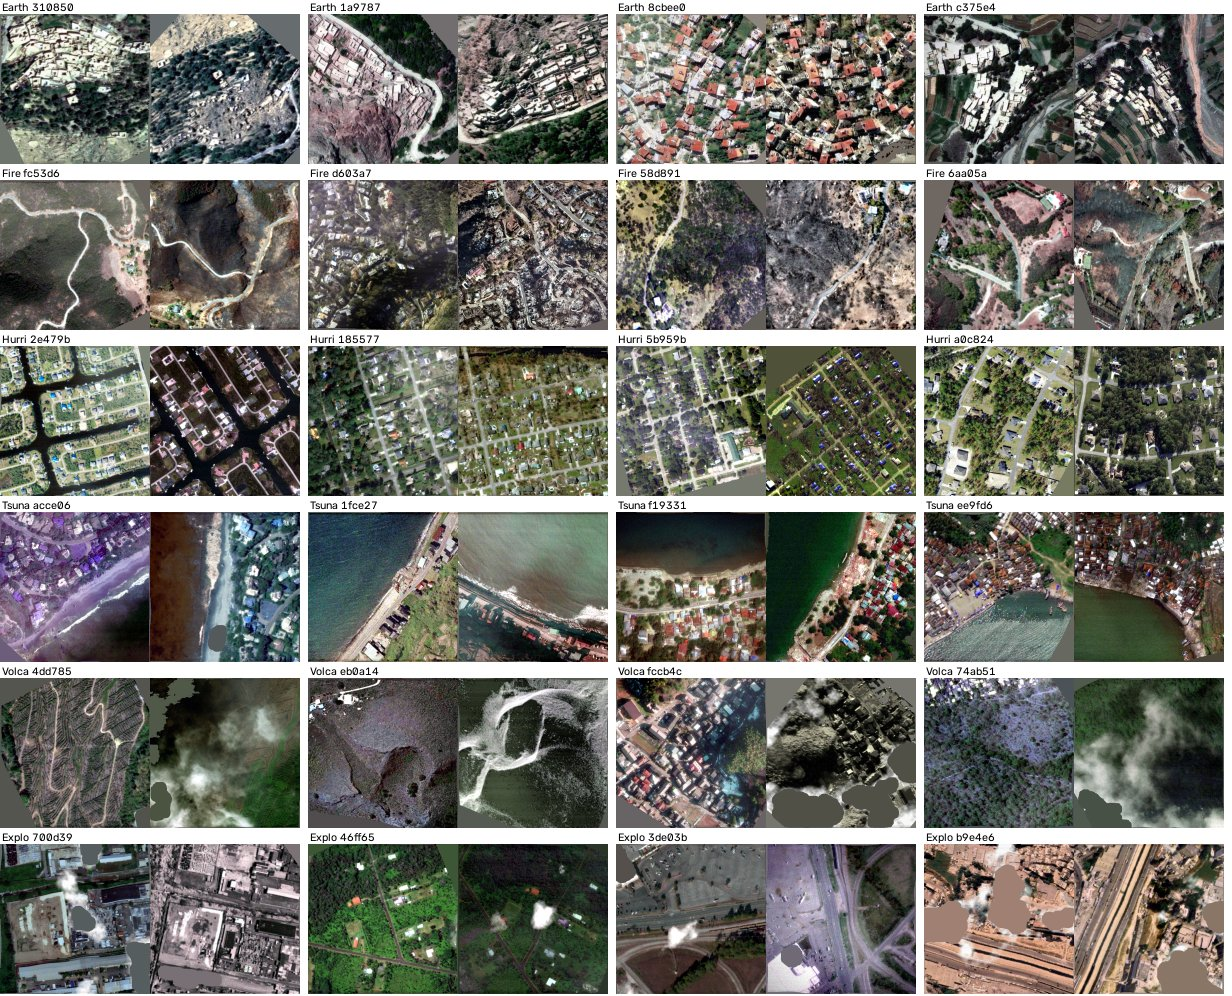

In [12]:
from common import montage
get_pre, get_post = vlm.load_src('clean512', True)
Z8 = sig['vlm_q8b_clean512'] - sig['vlm_q8b_clean512'].mean(0)
items = []
for k, c in enumerate(CLASSES):
    marg = Z8[:, k] - np.delete(Z8, k, 1).max(1)
    for i in np.argsort(-marg)[:4]:
        items.append((f'{c[:5]} {ids[i][:6]}', get_pre(i), get_post(i)))
montage(items, VIZ / 'q8b_class_exemplars_full.jpg', thumb=150, cols=4)
D(IPImage(str(VIZ / 'q8b_class_exemplars_full.jpg'), width=900))

### 6.2 Deconfounding: korupsi acak tidak boleh menentukan kelas

Contoh "Explosion" paling yakin dari 8B ternyata hampir semua berisi sisa gumpalan awan (dibaca sebagai asap), dan area
awan yang diisi warna rata-rata kadang dibaca sebagai abu atau bekas terbakar. Karena panitia menerapkan korupsi
**secara acak**, kelas sebenarnya tidak bergantung pada korupsi; ketergantungan skor pada variabel korupsi adalah bias.
Setiap sinyal terkalibrasi diregresikan pada kovariat korupsi (luas awan v1/v2, grayscale, padding, salt-and-pepper,
stripe, porsi piksel magenta) dan diambil residualnya. Koefisiennya disimpan di `models/` dan dipakai apa adanya saat inferensi.

In [13]:
from sklearn.linear_model import LinearRegression
Cov, cov_names = lm.noise_covariates()
rows = {}
for n in ['vlm_q8b_clean512', 'vlm_q4b_gray']:
    Zs = sig[n] - sig[n].mean(0); Zs /= Zs.std()
    rows[n] = [LinearRegression().fit(Cov, Zs[:, k]).score(Cov, Zs[:, k]) for k in range(6)]
print('R^2 skor kelas terhadap kovariat korupsi (sebelum deconfounding):')
display(pd.DataFrame(rows, index=CLASSES).T.round(3))

R^2 skor kelas terhadap kovariat korupsi (sebelum deconfounding):


,Earthquake,Fire,Hurricane,Tsunami,Volcano,Explosion
vlm_q8b_clean512,0.06,0.007,0.023,0.016,0.045,0.100
vlm_q4b_gray,0.06,0.010,0.034,0.012,0.046,0.059


### 6.3 Eksperimen yang ditolak: VLM tingkat event (mosaik 2x2)

Untuk tiap klaster KMeans (K=40), 4 tile dengan P(kerusakan) tertinggi disusun menjadi mosaik before/after dan dinilai
oleh 8B (`code/14_event_vlm.py`). Mosaik sepakat dengan rata-rata sinyal tile pada 65% klaster, tetapi **menurunkan**
kesepakatan dengan sinyal yang ditahan (tabel di bawah; makin besar bobotnya makin turun), dan 64% jawaban mentahnya
"Fire" (bias format mosaik). Karena itu tidak dipakai di model final.

In [14]:
tu = importlib.import_module('17_tune'); sc = importlib.import_module('13_selfcheck'); fin = importlib.import_module('15_final')
X = lm.event_features(); P = lm.knn_graph(X, cfg['k']); rel = lm.reliability(); m_all = np.ones(len(ids), bool)
Zc = {n: tu.calibrated(sig, n, Cov, 1) for n in sig}
def held_scores(extra=0, alpha=0.95, graph=True):
    Z1 = Zc['vlm_q8b_clean512'] + .25 * (Zc['clip_gray'] + Zc['clip_rgbn']) + extra   # predicts held-out 4B gray
    Z2 = Zc['vlm_q8b_clean512'] + Zc['vlm_q4b_gray'] + extra                         # predicts held-out CLIP
    if graph:
        Z1, Z2 = lm.propagate(P, Z1, rel, alpha, iters=200), lm.propagate(P, Z2, rel, alpha, iters=200)
    return [sc.score(Z1, Zc['vlm_q4b_gray'], m_all)[0], np.mean([sc.score(Z2, sig[h], m_all)[0] for h in ('clip_gray', 'clip_rgbn')])]
if (CACHE / 'evlm_q8b_k40.npz').exists():
    E = fin.event_signal(['q8b_k40'])
    res = {f'bobot event {we}': held_scores(we * E) for we in (0.0, 0.5, 1.0, 2.0)}
    display(pd.DataFrame(res, index=['ditahan: VLM 4B gray', 'ditahan: CLIP']).T.round(3))

,ditahan: VLM 4B gray,ditahan: CLIP
bobot event 0.0,0.589,0.220
bobot event 0.5,0.559,0.202
bobot event 1.0,0.538,0.190
bobot event 2.0,0.512,0.175


## 7. Label model (tanpa label)

1. **Kalibrasi** tiap sinyal: kurangi rata-rata per kelas, bagi simpangan baku global.
2. **Deconfounding** (bagian 6.2).
3. **Fusi** berbobot: VLM 8B warna 1,0; VLM 4B grayscale 1,0; CLIP perubahan warna 0,25 dan gray 0,25.
4. **Bobot keandalan**: bukti milik pasangan itu sendiri dikalikan (1 - awan_pre)(1 - awan_post)^2, minimal 0,1;
   pasangan yang tertutup awan mendapat label dari tetangga event-nya.
5. **Propagasi graf**: graf kNN (k=15) pada embedding event grayscale; F = (1-a)·C·Z + a·P·F, dinormalisasi dengan keyakinan
   yang ikut dipropagasi, a = 0,95.
6. **Prior kelas**: bias per kelas (Sinkhorn suhu rendah) agar porsi prediksi = target. Earthquake = 0,22 (dari skor
   sample submission). Kelas lain dari porsi tingkat *event*: tiap klaster KMeans (K = 20/40/80) diberi kelas argmax
   rata-rata skornya, porsinya dirata-rata, lalu disusutkan 30% ke arah seragam agar kelas langka tidak hilang
   (Macro F1 memberi F1 = 0 untuk kelas yang tidak pernah diprediksi). Estimasi tingkat event ini sendiri memberi
   Earthquake 0,21-0,26, konsisten dengan 0,22 dari halaman Evaluation.

**Validasi tanpa label.** Bila sinyal adalah pandangan berisik dari label yang sama dengan kesalahan yang relatif
independen, model yang lebih dekat ke kebenaran akan lebih sepakat dengan sinyal yang **ditahan** (tidak dipakai
membangun model). Dua arah dipakai karena masing-masing punya bias: VLM 4B ditahan (berbagi bias per tile dengan 8B,
condong ke propagasi lemah) dan CLIP ditahan (lebih independen, condong ke propagasi kuat). a = 0,95 adalah titik tengah.

In [15]:
res = {'tanpa graf': held_scores(graph=False)}
for a in (0.5, 0.8, 0.9, 0.95, 0.97, 0.99):
    res[f'propagasi a={a}'] = held_scores(alpha=a)
print('korelasi rank per kelas dengan sinyal yang ditahan:')
display(pd.DataFrame(res, index=['ditahan: VLM 4B gray', 'ditahan: CLIP']).T.round(3))

korelasi rank per kelas dengan sinyal yang ditahan:


,ditahan: VLM 4B gray,ditahan: CLIP
tanpa graf,0.563,0.170
propagasi a=0.5,0.608,0.194
propagasi a=0.8,0.614,0.211
propagasi a=0.9,0.603,0.217
propagasi a=0.95,0.589,0.220
propagasi a=0.97,0.578,0.220
propagasi a=0.99,0.557,0.217


## 8. Prediksi dan submission

In [16]:
pred, S = t2pipe.predict(TAG)
sub = t2pipe.write_submission(pred, ROOT / 'submission.csv')
display(sub.head())
display(sub.Phenomenon.value_counts().reindex(CLASSES).to_frame('jumlah').assign(porsi=lambda d: (d.jumlah / len(sub)).round(3)))

,Id,Phenomenon
0,000c166d1af6,Volcano
1,0047c432f3c2,Earthquake
2,006b070b2644,Volcano
3,0087328f3429,Volcano
4,00cc6cf40768,Fire


,jumlah,porsi
Phenomenon,,
Earthquake,702,0.221
Fire,533,0.168
Hurricane,536,0.169
Tsunami,272,0.086
Volcano,949,0.298
Explosion,188,0.059


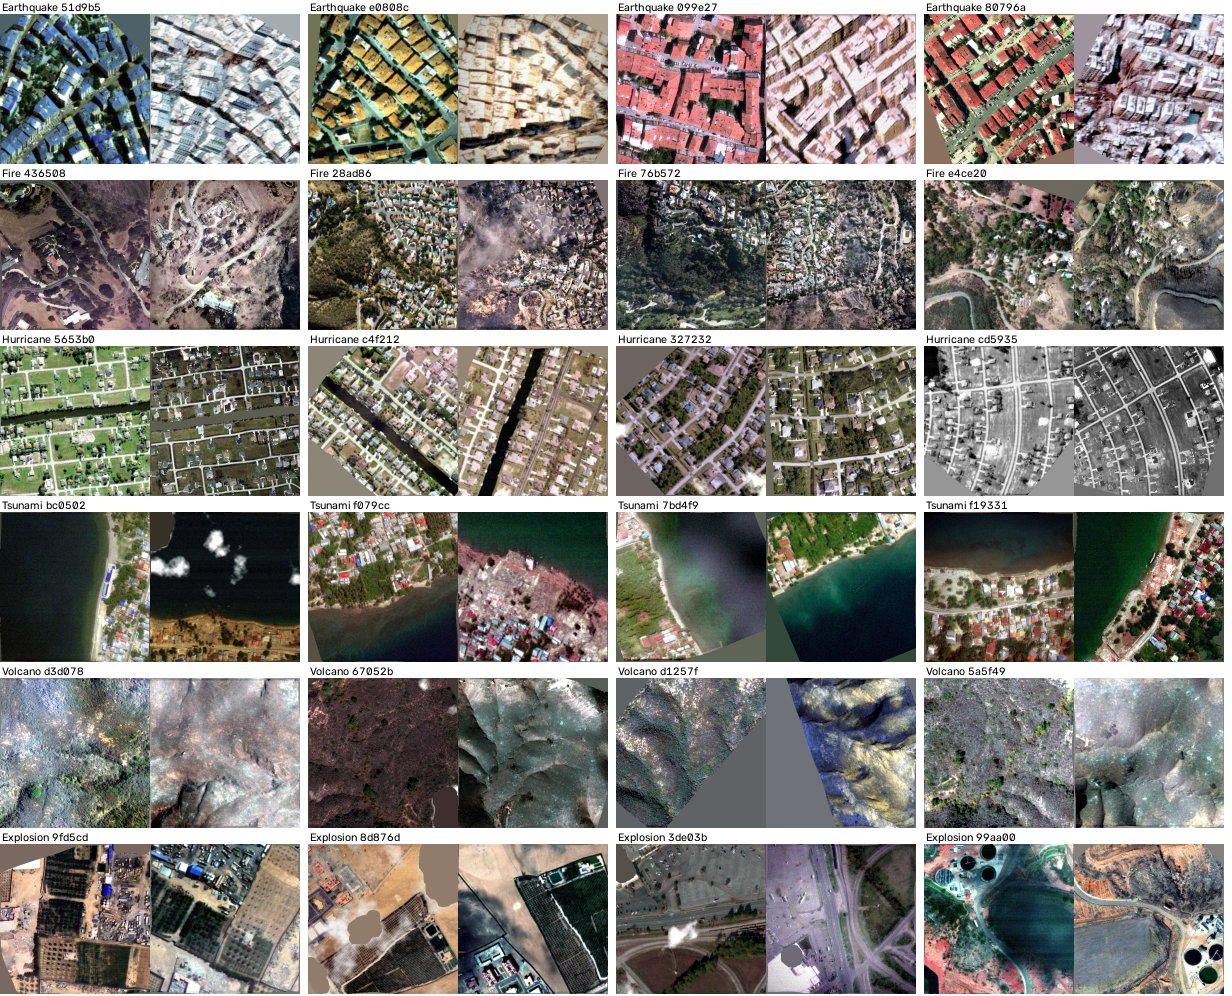

In [17]:
from common import montage
get_pre, get_post = vlm.load_src('clean512', True)
margin = np.sort(S, 1)[:, -1] - np.sort(S, 1)[:, -2]
items = []
for k, c in enumerate(CLASSES):
    idx = np.where(pred == k)[0]
    for i in idx[np.argsort(-margin[idx])][:4]:
        items.append((f'{c} {ids[i][:6]}', get_pre(i), get_post(i)))
montage(items, VIZ / 'final_per_class.jpg', thumb=150, cols=4)
D(IPImage(str(VIZ / 'final_per_class.jpg'), width=950))

Konsistensi tingkat event: di tiap pulau HDBSCAN, berapa porsi pasangan yang mendapat kelas dominan pulau itu.
Pulau kota padat → Earthquake, garis pantai → Tsunami, permukiman pesisir Teluk AS → Hurricane, lereng gersang berabu → Volcano.

In [18]:
lab_h = np.load(CACHE / 'hdb_labels.npy')
rows = []
for h in range(lab_h.max() + 1):
    idx = lab_h == h; shr = np.bincount(pred[idx], minlength=6) / idx.sum()
    rows.append((f'h{h}', int(idx.sum()), CLASSES[shr.argmax()], round(shr.max(), 2)))
isl = pd.DataFrame(rows, columns=['pulau', 'n', 'kelas dominan', 'porsi'])
print('rata-rata (berbobot n) porsi kelas dominan per pulau:', round((isl.porsi * isl.n).sum() / isl.n.sum(), 3))
display(isl.sort_values('n', ascending=False).head(15))

rata-rata (berbobot n) porsi kelas dominan per pulau: 0.755


,pulau,n,kelas dominan,porsi
13,h13,192,Volcano,0.55
0,h0,182,Earthquake,0.98
24,h24,172,Volcano,0.96
20,h20,142,Volcano,0.70
5,h5,126,Earthquake,0.90
22,h22,107,Volcano,0.99
29,h29,88,Volcano,0.55
4,h4,86,Fire,0.42
2,h2,83,Earthquake,0.93
16,h16,81,Fire,0.72


## 9. Kesimpulan, keterbatasan, dan cara menjalankan

* **Tanpa label**, solusi bertumpu pada (1) pembersihan noise yang terukur, (2) embedding tahan-artefak untuk menemukan
  struktur event, (3) bukti zero-shot dari beberapa model yang biasnya dikalibrasi dan dibersihkan dari pengaruh korupsi,
  dan (4) propagasi di graf event plus prior kelas yang dijangkarkan pada informasi Earthquake ≈ 22%.
* **Keterbatasan:** akurasi zero-shot per tile terbatas dan tidak bisa diukur langsung tanpa label; kelas yang mirip
  (Fire vs Volcano pada lereng gersang, Earthquake vs Explosion di kota, Hurricane vs Tsunami di pesisir) paling rawan
  tertukar; porsi kelas selain Earthquake tidak diketahui dan diperkirakan dari data.
* **Tidak ada label manual**: tidak ada satu pun prediksi yang diisi tangan; inspeksi visual hanya dipakai untuk EDA.
* **Menjalankan:** `pip install -r requirements.txt` (PyTorch CUDA dari index cu128), letakkan dataset di
  `Datasets/` (struktur asli), lalu jalankan notebook dari atas. Dengan cache `exp/cache/` lengkap notebook selesai dalam
  beberapa menit; dari nol sekitar 4-5 jam di RTX 3060 (paling lama: dua run VLM, ~2 jam dan ~1,2 jam).
* Parameter label model: `models/label_model_final.npz` dan `models/label_model_final.json`.